# The Analysis of Token Level Probabilities
Now that I have computed the token-level probabilities, I want to assess their range and the differences (if any) between my chosen programming languages. 

In [24]:
import os
import pandas as pd
import numpy as np
from scipy.stats import rankdata
from scipy.stats import wilcoxon
import plotly.graph_objects as go

In [2]:
python_probs = pd.read_csv('datasets/all_probabilities.csv')

In [3]:
python_probs.head()

,title,line_number,line_text,token_prob,similarity_2,similarity_3,similarity_4,similarity_5,rf_with_sim,rf_without_sim
0,A+B Again?,1,t = int(input())\n\n,0.935992,0.898168,0.849335,0.858385,0.862048,0.508929,0.375000
1,A+B Again?,2,for _ in range(t):\n,0.993529,0.769206,0.735990,0.821829,0.860018,0.752382,0.875000
2,A+B Again?,3,n = int(input())\n,0.999838,0.932981,0.804449,0.845420,0.874074,0.678571,0.678571
3,A+B Again?,4,tens_digit = n // 10\n \n,0.998948,0.772575,0.777754,0.831880,0.856383,0.848214,0.928571
4,A+B Again?,5,units_digit = n % 10\n \n,0.999998,0.817759,0.815602,0.854043,0.862512,0.830357,0.946429


## Quality Check
Have all lines a computed probability?

In [4]:
python_csv_file = '/datasets/selected_problems_python_14B_no_comments_final.csv'

def get_generated_code(csv_file):
    csv_full_path = os.getcwd()+csv_file
    if os.path.exists(csv_full_path):
        return pd.read_csv(csv_full_path)
    else:
        print("File not found.")
        return None
    
python_solutions = get_generated_code(python_csv_file)

In [5]:
python_probs['line_text'] = python_probs['line_text'].str.strip()

def check_line_probs(df, probs, comment):
    for index, row in df.iterrows():
        lines = row['solution'].split('\n')
        for line in lines:
            line = line.strip()
            matched_rows = probs.loc[(probs['line_text'] == line) & (probs['title'] == row['title'])]
            if matched_rows.empty and not line.startswith(comment) and not line.isspace() and line != '':
                print(row)
                print(f"Line: {line}")

In [6]:
check_line_probs(python_solutions, python_probs, '#')

# Overall Analysis

In [7]:
def get_stats(df, prob):
    overall_stats = df[prob].agg(['min', 'max', 'mean', 'median', 'std'])
    return overall_stats

In [8]:
stats = get_stats(python_probs, 'rf_with_sim')

print("Overall token_prob stats:")
print(stats)

Overall token_prob stats:
min       0.044643
max       1.000000
mean      0.831831
median    0.910714
std       0.198468
Name: rf_with_sim, dtype: float64


In [9]:
data = {
    "token_prob": get_stats(python_probs, 'token_prob'),
    "similarity_2": get_stats(python_probs, f'similarity_2'),
    "similarity_3": get_stats(python_probs, f'similarity_3'),
    "similarity_4": get_stats(python_probs, f'similarity_4'),
    "similarity_5": get_stats(python_probs, f'similarity_5'),
    "rf_with_sim": get_stats(python_probs, 'rf_with_sim'),
    "rf_without_sim": get_stats(python_probs, 'rf_without_sim')
}

In [10]:
for i in range(2, 6):
    print(f'Similarity {i}')
    stats = get_stats(python_probs, f'similarity_{i}')

    print(f"Min: {stats[0]}, Max: {stats[1]}")
    print("Overall token_prob stats:")
    print(stats[2])

Similarity 2
Min: -0.0454437956213951, Max: 1.000000238418579
Overall token_prob stats:
0.7553736273375949
Similarity 3
Min: 0.087679237127304, Max: 1.000000238418579
Overall token_prob stats:
0.7543495519921697
Similarity 4
Min: 0.0795100554823875, Max: 1.000000238418579
Overall token_prob stats:
0.7498283111650882
Similarity 5
Min: 0.0994904562830925, Max: 1.000000238418579
Overall token_prob stats:
0.7520286988402749


/tmp/ipykernel_338/3816274578.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"Min: {stats[0]}, Max: {stats[1]}")
/tmp/ipykernel_338/3816274578.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(stats[2])


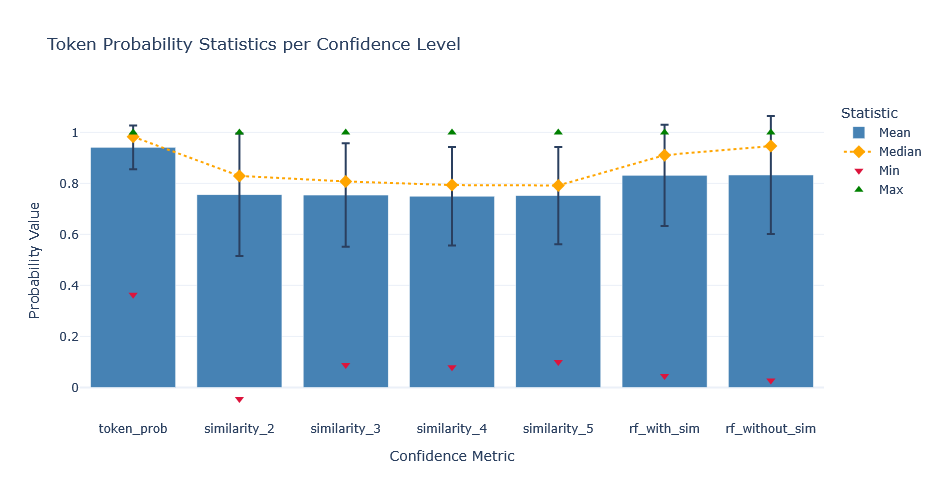

In [11]:
df = pd.DataFrame(data).T.reset_index().rename(columns={"index": "Confidence"})

# Plot
fig = go.Figure()

# Mean with std error bars
fig.add_trace(go.Bar(
    x=df['Confidence'],
    y=df['mean'],
    name='Mean',
    error_y=dict(type='data', array=df['std'], visible=True),
    marker_color='steelblue'
))

# Median as scatter
fig.add_trace(go.Scatter(
    x=df['Confidence'],
    y=df['median'],
    mode='markers+lines',
    name='Median',
    marker=dict(color='orange', symbol='diamond', size=10),
    line=dict(dash='dot')
))

# Min and max as scatter points
fig.add_trace(go.Scatter(
    x=df['Confidence'],
    y=df['min'],
    mode='markers',
    name='Min',
    marker=dict(color='crimson', symbol='triangle-down', size=8)
))

fig.add_trace(go.Scatter(
    x=df['Confidence'],
    y=df['max'],
    mode='markers',
    name='Max',
    marker=dict(color='green', symbol='triangle-up', size=8)
))

fig.update_layout(
    title='Token Probability Statistics per Confidence Level',
    xaxis_title='Confidence Metric',
    yaxis_title='Probability Value',
    template='plotly_white',
    legend_title='Statistic',
    height=500
)

fig.show()

In [12]:
x = 0.5
total_python_rows = len(python_probs)
count = (python_probs['token_prob'] < x).sum()
print(f"Number of values lower than {x}: {count} out of {total_python_rows}")

Number of values lower than 0.5: 2 out of 1160


In [13]:
x = 0.5
total_python_rows = len(python_probs)
count = (python_probs['similarity_2'] < x).sum()
print(f"Number of values lower than {x}: {count} out of {total_python_rows}")

Number of values lower than 0.5: 189 out of 1160


# Difficulty-Level Analysis
I also need the selected problems to make a comparison between the probabilties based on the difficulty level.

In [14]:
csv_file = '/datasets/selected_problems.csv'
csv_full_path = os.getcwd()+csv_file
if os.path.exists(csv_full_path):
    selected_problems = pd.read_csv(csv_full_path)
else:
    selected_problems = None
    print("File not found.")

In [15]:
selected_problems.head()

,title,description,difficulty,source
0,Sports Rank,Sports leagues rank their participants (teams ...,Medium,Kattis
1,Solidus Fraction,A fraction written with a solidus (/) can be w...,Medium,Kattis
2,Breakout,A variant of the popular video game breakout u...,Medium,Kattis
3,Passport Dates,Konráð has managed to obtain a big pile of Ice...,Easy,Kattis
4,Weather Forecast,One of the most important things you can do in...,Hard,Kattis


In [16]:
def merge_dfs(df):
    python_probs_merged = pd.merge(df, selected_problems, on='title')
    python_probs_merged = python_probs_merged.drop(['line_number', 'line_text', 'description', 'title'], axis=1)
    return python_probs_merged

In [17]:
python_probs_merged = merge_dfs(python_probs)
difficulty_order = ['Easy', 'Medium', 'Hard']
python_probs_merged['difficulty'] = pd.Categorical(python_probs_merged['difficulty'], categories=difficulty_order, ordered=True)
python_probs_merged.head()

,token_prob,similarity_2,similarity_3,similarity_4,similarity_5,rf_with_sim,rf_without_sim,difficulty,source
0,0.935992,0.898168,0.849335,0.858385,0.862048,0.508929,0.375000,Easy,CodeForces
1,0.993529,0.769206,0.735990,0.821829,0.860018,0.752382,0.875000,Easy,CodeForces
2,0.999838,0.932981,0.804449,0.845420,0.874074,0.678571,0.678571,Easy,CodeForces
3,0.998948,0.772575,0.777754,0.831880,0.856383,0.848214,0.928571,Easy,CodeForces
4,0.999998,0.817759,0.815602,0.854043,0.862512,0.830357,0.946429,Easy,CodeForces


In [29]:
def get_p_value(difficulties, confidence):
    confidences_1 = python_probs_merged[python_probs_merged['difficulty'] == difficulties[0]][confidence].to_list()
    confidences_2 = python_probs_merged[python_probs_merged['difficulty'] == difficulties[1]][confidence].to_list()
    return wilcoxon(confidences_1, confidences_2)

In [43]:
from scipy.stats import levene

def get_homogeneity(df, confidence):
    easy = df[df['difficulty'] == 'Easy'][confidence]
    medium = df[df['difficulty'] == 'Medium'][confidence]
    hard = df[df['difficulty'] == 'Hard'][confidence]

    stat, p = levene(easy, medium, hard)
    print(f"Levene's test for {confidence}: p = {p:.4f}")
    
get_homogeneity(python_probs_merged, 'token_prob')
get_homogeneity(python_probs_merged, 'similarity_2')
get_homogeneity(python_probs_merged, 'similarity_3')
get_homogeneity(python_probs_merged, 'similarity_4')
get_homogeneity(python_probs_merged, 'similarity_5')
get_homogeneity(python_probs_merged, 'rf_with_sim')
get_homogeneity(python_probs_merged, 'rf_without_sim')

Levene's test for token_prob: p = 0.1316
Levene's test for similarity_2: p = 0.0000
Levene's test for similarity_3: p = 0.0000
Levene's test for similarity_4: p = 0.0000
Levene's test for similarity_5: p = 0.0000
Levene's test for rf_with_sim: p = 0.2680
Levene's test for rf_without_sim: p = 0.4629


In [44]:
from scipy.stats import shapiro

def get_normality(df, confidence):
    for group in df['difficulty'].unique():
        stat, p = shapiro(df[df['difficulty'] == group][confidence])
        print(f"Shapiro-Wilk {group} for {confidence}: p = {p:.4f}")

get_normality(python_probs_merged, 'token_prob')
get_normality(python_probs_merged, 'similarity_2')
get_normality(python_probs_merged, 'similarity_3')
get_normality(python_probs_merged, 'similarity_4')
get_normality(python_probs_merged, 'similarity_5')
get_normality(python_probs_merged, 'rf_with_sim')
get_normality(python_probs_merged, 'rf_without_sim')

Shapiro-Wilk Easy for token_prob: p = 0.0000
Shapiro-Wilk Medium for token_prob: p = 0.0000
Shapiro-Wilk Hard for token_prob: p = 0.0000
Shapiro-Wilk Easy for similarity_2: p = 0.0000
Shapiro-Wilk Medium for similarity_2: p = 0.0000
Shapiro-Wilk Hard for similarity_2: p = 0.0000
Shapiro-Wilk Easy for similarity_3: p = 0.0000
Shapiro-Wilk Medium for similarity_3: p = 0.0000
Shapiro-Wilk Hard for similarity_3: p = 0.0000
Shapiro-Wilk Easy for similarity_4: p = 0.0000
Shapiro-Wilk Medium for similarity_4: p = 0.0000
Shapiro-Wilk Hard for similarity_4: p = 0.0000
Shapiro-Wilk Easy for similarity_5: p = 0.0000
Shapiro-Wilk Medium for similarity_5: p = 0.0000
Shapiro-Wilk Hard for similarity_5: p = 0.0000
Shapiro-Wilk Easy for rf_with_sim: p = 0.0000
Shapiro-Wilk Medium for rf_with_sim: p = 0.0000
Shapiro-Wilk Hard for rf_with_sim: p = 0.0000
Shapiro-Wilk Easy for rf_without_sim: p = 0.0000
Shapiro-Wilk Medium for rf_without_sim: p = 0.0000
Shapiro-Wilk Hard for rf_without_sim: p = 0.0000


In [50]:
from scipy.stats import kruskal

def do_kruskal(df, confidence):
    kruskal_value = kruskal(
        df[df['difficulty'] == 'Easy'][confidence],
        df[df['difficulty'] == 'Medium'][confidence],
        df[df['difficulty'] == 'Hard'][confidence]
    )
    print(f'Kruskal for {confidence}: {kruskal_value.pvalue} - is <= 0.05? {kruskal_value.pvalue <= 0.05}')
          
do_kruskal(python_probs_merged, 'token_prob')
do_kruskal(python_probs_merged, 'similarity_2')
do_kruskal(python_probs_merged, 'similarity_3')
do_kruskal(python_probs_merged, 'similarity_4')
do_kruskal(python_probs_merged, 'similarity_5')
do_kruskal(python_probs_merged, 'rf_with_sim')
do_kruskal(python_probs_merged, 'rf_without_sim')

Kruskal for token_prob: 0.11290941964470509 - is <= 0.05? False
Kruskal for similarity_2: 5.688162197230804e-10 - is <= 0.05? True
Kruskal for similarity_3: 3.566796220512236e-14 - is <= 0.05? True
Kruskal for similarity_4: 2.5208304129453886e-20 - is <= 0.05? True
Kruskal for similarity_5: 2.4230420666226558e-18 - is <= 0.05? True
Kruskal for rf_with_sim: 0.09352698580560716 - is <= 0.05? False
Kruskal for rf_without_sim: 0.22513279653172064 - is <= 0.05? False


In [53]:
def compute_epsilon_squared(df, confidence):
    N = len(df)
    H, _ = kruskal(
        df[df['difficulty'] == 'Easy'][confidence],
        df[df['difficulty'] == 'Medium'][confidence],
        df[df['difficulty'] == 'Hard'][confidence]
    )
    print(f'Epsilon Squared for {confidence}: {(H - 1) / (N - 1)}')

compute_epsilon_squared(python_probs_merged, 'token_prob')
compute_epsilon_squared(python_probs_merged, 'similarity_2')
compute_epsilon_squared(python_probs_merged, 'similarity_3')
compute_epsilon_squared(python_probs_merged, 'similarity_4')
compute_epsilon_squared(python_probs_merged, 'similarity_5')
compute_epsilon_squared(python_probs_merged, 'rf_with_sim')
compute_epsilon_squared(python_probs_merged, 'rf_without_sim')

Epsilon Squared for token_prob: 0.0029010688141229888
Epsilon Squared for similarity_2: 0.03587137829535553
Epsilon Squared for similarity_3: 0.05257035983825448
Epsilon Squared for similarity_4: 0.07700968677082613
Epsilon Squared for similarity_5: 0.06913116112308816
Epsilon Squared for rf_with_sim: 0.003226066032938637
Epsilon Squared for rf_without_sim: 0.0017102068059941433


In [18]:
range_by_difficulty_python = python_probs_merged.groupby('difficulty')['token_prob'].agg(['min', 'max', 'mean', 'median', 'std'])
print(range_by_difficulty_python)

                 min       max      mean    median       std
difficulty                                                  
Easy        0.591162  0.999999  0.935206  0.982662  0.090595
Medium      0.363185  1.000000  0.948133  0.987634  0.085235
Hard        0.558246  1.000000  0.939489  0.978605  0.083880


/tmp/ipykernel_338/278465460.py:1: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [19]:
range_by_difficulty_sim_2 = python_probs_merged.groupby('difficulty')['similarity_2'].agg(['min', 'max', 'mean', 'median', 'std'])
print(range_by_difficulty_sim_2)

                 min  max      mean    median       std
difficulty                                             
Easy        0.378284  1.0  0.854383  0.887958  0.134429
Medium     -0.045444  1.0  0.729990  0.825415  0.258616
Hard       -0.008786  1.0  0.724693  0.801929  0.252944


/tmp/ipykernel_338/2191679362.py:1: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [20]:
range_by_difficulty_sim_3 = python_probs_merged.groupby('difficulty')['similarity_3'].agg(['min', 'max', 'mean', 'median', 'std'])
print(range_by_difficulty_sim_3)

                 min  max      mean    median       std
difficulty                                             
Easy        0.331526  1.0  0.843882  0.868086  0.127155
Medium      0.087679  1.0  0.733697  0.797797  0.226768
Hard        0.094367  1.0  0.724755  0.776136  0.201006


/tmp/ipykernel_338/2256613556.py:1: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [21]:
data = {
    "token_prob": python_probs_merged.groupby('difficulty')['token_prob'].agg(['min', 'max', 'mean', 'median', 'std']),
    "similarity_2": python_probs_merged.groupby('difficulty')['similarity_2'].agg(['min', 'max', 'mean', 'median', 'std']),
    "similarity_3": python_probs_merged.groupby('difficulty')['similarity_3'].agg(['min', 'max', 'mean', 'median', 'std']),
    "similarity_4": python_probs_merged.groupby('difficulty')['similarity_4'].agg(['min', 'max', 'mean', 'median', 'std']),
    "similarity_5": python_probs_merged.groupby('difficulty')['similarity_5'].agg(['min', 'max', 'mean', 'median', 'std']),
    "rf_with_sim": python_probs_merged.groupby('difficulty')['rf_with_sim'].agg(['min', 'max', 'mean', 'median', 'std']),
    "rf_without_sim": python_probs_merged.groupby('difficulty')['rf_without_sim'].agg(['min', 'max', 'mean', 'median', 'std'])
}

/tmp/ipykernel_338/335359252.py:2: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_338/335359252.py:3: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_338/335359252.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_338/335359252.py:5: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to reta

In [22]:
# Build one DataFrame
df_list = []
for metric, df in data.items():
    tmp = df.copy().reset_index()  # bring difficulty back as a column
    tmp['metric'] = metric
    df_list.append(tmp)

df_stats = pd.concat(df_list, ignore_index=True)
df_stats

,difficulty,min,max,mean,median,std,metric
0,Easy,0.591162,0.999999,0.935206,0.982662,0.090595,token_prob
1,Medium,0.363185,1.000000,0.948133,0.987634,0.085235,token_prob
2,Hard,0.558246,1.000000,0.939489,0.978605,0.083880,token_prob
3,Easy,0.378284,1.000000,0.854383,0.887958,0.134429,similarity_2
4,Medium,-0.045444,1.000000,0.729990,0.825415,0.258616,similarity_2
5,Hard,-0.008786,1.000000,0.724693,0.801929,0.252944,similarity_2
6,Easy,0.331526,1.000000,0.843882,0.868086,0.127155,similarity_3
7,Medium,0.087679,1.000000,0.733697,0.797797,0.226768,similarity_3
8,Hard,0.094367,1.000000,0.724755,0.776136,0.201006,similarity_3
9,Easy,0.339444,1.000000,0.836165,0.854745,0.125019,similarity_4


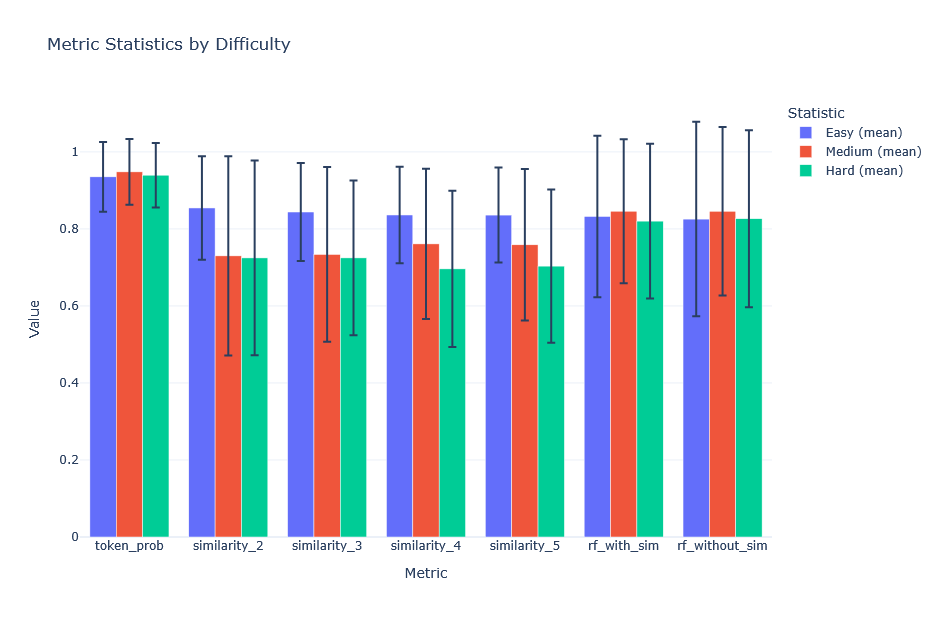

In [23]:
import pandas as pd
import plotly.graph_objects as go

# Step 1: Flatten your dict into a DataFrame
df_list = []
for metric, df in data.items():
    df = df.copy().reset_index()  # bring 'difficulty' back
    df['metric'] = metric
    df_list.append(df)

df_stats = pd.concat(df_list, ignore_index=True)
difficulty_order = ['Easy', 'Medium', 'Hard']
df_stats['difficulty'] = pd.Categorical(df_stats['difficulty'], categories=difficulty_order, ordered=True)

# Step 2: Create a grouped bar chart (mean ± std) per metric
difficulties = df_stats['difficulty'].unique()
metrics = df_stats['metric'].unique()

fig = go.Figure()

# Add mean bars per difficulty for each metric
for diff in difficulties:
    subset = df_stats[df_stats['difficulty'] == diff]
    fig.add_trace(
        go.Bar(
            x=subset['metric'],
            y=subset['mean'],
            name=f"{diff} (mean)",
            error_y=dict(type='data', array=subset['std']),
        )
    )

# # Optional: Add median, min, and max as scatter markers
# # They will be overlaid on top of bars
# fig.add_trace(
#     go.Scatter(
#         x=df_stats['metric'],
#         y=df_stats['median'],
#         mode='markers',
#         name='Median',
#         marker=dict(symbol='diamond', size=10, color='black'),
#         showlegend=True
#     )
# )
# fig.add_trace(
#     go.Scatter(
#         x=df_stats['metric'],
#         y=df_stats['min'],
#         mode='markers',
#         name='Min',
#         marker=dict(symbol='triangle-down', size=8, color='red'),
#         showlegend=True
#     )
# )
# fig.add_trace(
#     go.Scatter(
#         x=df_stats['metric'],
#         y=df_stats['max'],
#         mode='markers',
#         name='Max',
#         marker=dict(symbol='triangle-up', size=8, color='green'),
#         showlegend=True
#     )
# )

# Step 3: Layout adjustments
fig.update_layout(
    barmode='group',
    title='Metric Statistics by Difficulty',
    xaxis_title='Metric',
    yaxis_title='Value',
    legend_title='Statistic',
    template='plotly_white',
    height=600,
    width=1000
)

fig.show()